# Replication of the main results

*Does the transmission of external shocks depend on the state of business confidence? Evidence for Peru, 2002-2025* (Sánchez and Vassallo).

This notebook re-estimates the two baseline threshold VARs and reproduces, step by step, **Figure 1** (business confidence and the pessimism months), **Figure 2** (the variables of the model), **Table 2** (pass-through and posterior probability of the asymmetry), **Figure 3** (GDP response by regime) and **Figure 6** (the structural model against the TVAR). Every other figure and table of the paper and of the appendix is produced by `make all` (about 10 minutes); see `README.md`.

Requirements: `pip install -e .` in this folder (MacroPy 0.3.3 is pulled from its released wheel; `irispie` solves the structural model). Running time: about two minutes on a laptop. All specification choices are read from `config.toml`; the figure and table labels are in Spanish, as in the paper.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tvar_shocks import data, load_config, model_specs, structural
from tvar_shocks.figures import LABELS, REGIME, STYLE, _band, _shade_below, _years, _zero
from tvar_shocks.model import asymmetry, fit, girfs, pass_through

%matplotlib inline

cfg = load_config()
db = data.load()
g = cfg["girf"]
specs = model_specs(cfg)
pd.DataFrame({k: {"variables": ", ".join(s.variables), "shock (pp)": s.shock, "threshold": s.threshold,
                  "lags": s.lags, "sample": f"{s.start[:7]} to {s.end[:7]}"} for k, s in specs.items()}).T

,variables,shock (pp),threshold,lags,sample
chn,"g_ip_chn, g_gdp, g_cpi, int, exp",1.0,50.0,2,2002-04 to 2025-12
ipx,"g_xpi, g_gdp, g_cpi, int, exp",10.0,50.0,2,2002-04 to 2025-12


## 1. Data

### Figure 1: business confidence and the pessimism regime

The BCRP's three-month expectations index for the economy. The regime is pessimism when the index, `d` months earlier, is at or below 50 points; the shaded areas mark the months below 50.

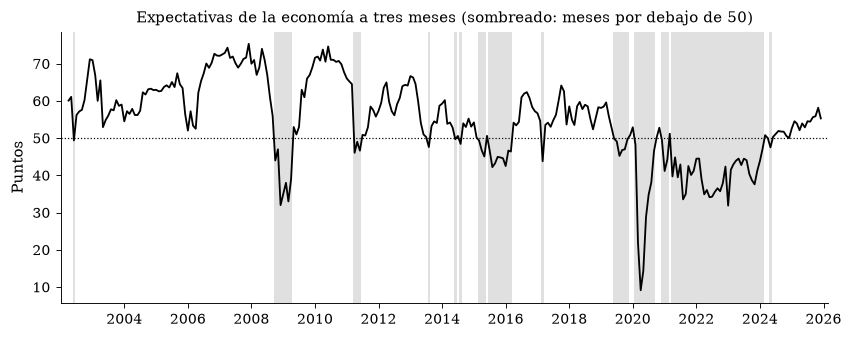

Months at or below 50 points: 82 of 285


In [2]:
sample = db.loc[cfg["data"]["start"]:cfg["data"]["end"]]
threshold = cfg["estimation"]["threshold"]
with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(9, 3.2))
    _shade_below(ax, sample["exp"], threshold)
    ax.plot(sample.index, sample["exp"], color="0", lw=1.2)
    ax.axhline(threshold, color="0", lw=0.8, ls=":")
    ax.set_ylabel("Puntos")
    ax.set_title("Expectativas de la economía a tres meses (sombreado: meses por debajo de 50)")
    _years(ax, 2)
    ax.margins(x=0.01)
plt.show()
print(f"Months at or below {threshold:g} points: {(sample['exp'] <= threshold).sum()} of {len(sample)}")

### Figure 2: the variables of the baseline models

Year-on-year growth rates, the interbank rate in percent and confidence in points. The shaded area is the pandemic window that the estimation takes out of the likelihood (diffuse dummies for January 2020 to June 2021 plus the two months whose lags fall in that window).

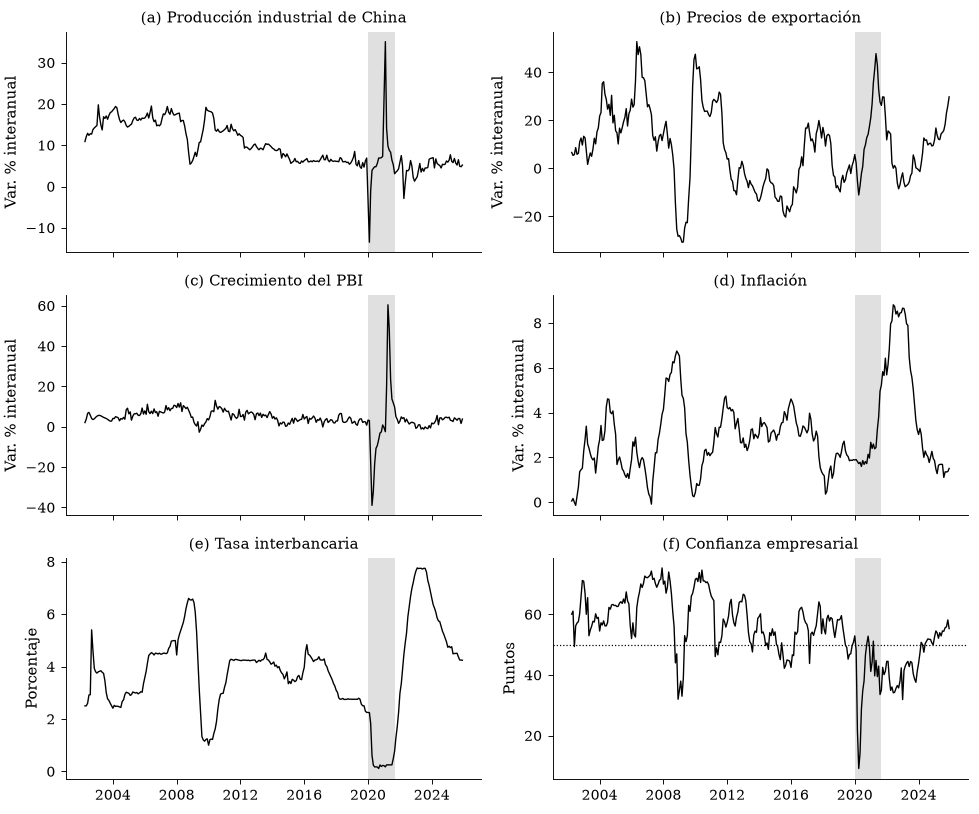

In [3]:
cols = ["g_ip_chn", "g_xpi", "g_gdp", "g_cpi", "int", "exp"]
w = cfg["covid"]["window"]
covid = (pd.Timestamp(f"{w[0]}-01"), pd.Timestamp(f"{w[1]}-01") + pd.DateOffset(months=2) + pd.offsets.MonthEnd(0))
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(3, 2, figsize=(9, 7.5), sharex=True)
    for ax, c, letter in zip(axes.ravel(), cols, "abcdef"):
        ax.axvspan(*covid, color="0.88", lw=0, zorder=0)
        ax.plot(sample.index, sample[c], color="0", lw=0.9)
        if c == "exp":
            ax.axhline(threshold, color="0", lw=0.8, ls=":")
        ax.set_title(f"({letter}) {LABELS[c]}")
        ax.set_ylabel({"int": "Porcentaje", "exp": "Puntos"}.get(c, "Var. % interanual"))
        _years(ax, 4)
    fig.tight_layout()
plt.show()

## 2. Baseline models

One threshold VAR per external shock, with the external variable ordered first. The threshold is fixed at 50 points of the confidence index, the delay is estimated (uniform prior on 1 to 6), the prior hyperparameters are the ones chosen by marginal likelihood in `config.toml`, and the pandemic months are dummied out. MacroPy's sampler is exact: the draws are independent and explosive ones are rejected.

In [4]:
models, resp = {}, {}
for name, spec in specs.items():
    models[name] = fit(spec, db, g["horizon"])
    resp[name] = girfs(models[name], spec, g["n_draws"], g["reps"])
    lml = models[name].log_marginal_likelihood()
    p_low = 1.0 - models[name].regime_probability()
    print(f"{name}: T = {models[name].T}, months in pessimism = {int((p_low > 0.5).sum())}, "
          f"delay (median) = {int(np.median(models[name].draws['delay']))}, "
          f"stable share = {models[name].stable_share:.2f}, log Bayes factor = {lml['log Bayes factor']:.1f}")

chn: T = 259, months in pessimism = 67, delay (median) = 4, stable share = 0.41, log Bayes factor = 2.1


ipx: T = 259, months in pessimism = 67, delay (median) = 4, stable share = 0.52, log Bayes factor = -12.8


### Table 2: pass-through to GDP and posterior probability of the asymmetry

Cumulative response of GDP growth over the cumulative response of the external variable, scaled to the size of the shock, draw by draw: median and 68% interval by regime, and the posterior probability that the pass-through is larger under optimism.

In [5]:
rows = []
for name, spec in specs.items():
    asym = asymmetry(resp[name], spec, g["pass_through"])
    for reg in ("pesimismo", "optimismo"):
        pt = pass_through(resp[name][reg], spec, g["pass_through"])
        for H in g["pass_through"]:
            rows.append({"shock": spec.short, "regime": reg, "horizon": H,
                         "median": round(pt.loc[H, "p50"], 2),
                         "68% interval": f"[{pt.loc[H, 'p16']:.2f}, {pt.loc[H, 'p84']:.2f}]",
                         "Pr(optimism > pessimism)": round(asym.loc[H, "prob_optimism_larger"], 2)})
table2 = pd.DataFrame(rows).set_index(["shock", "regime", "horizon"])
table2

median   68% interval  Pr(optimism > pessimism)
shock regime    horizon                                                 
China pesimismo 12         0.20   [0.12, 0.30]                      0.56
                24         0.30   [0.19, 0.42]                      0.50
                60         0.33   [0.14, 0.54]                      0.56
      optimismo 12         0.22   [0.15, 0.28]                      0.56
                24         0.31   [0.23, 0.39]                      0.50
                60         0.36   [0.20, 0.54]                      0.56
IPX   pesimismo 12         0.32   [0.04, 0.61]                      0.85
                24         0.38   [0.00, 0.82]                      0.92
                60         0.26  [-0.93, 1.17]                      0.87
      optimismo 12         0.59   [0.38, 0.84]                      0.85
                24         0.93   [0.60, 1.32]                      0.92
                60         1.18   [0.41, 2.33]                      0.87

### Figure 3: GDP response by regime

Generalized impulse responses (Koop, Pesaran and Potter, 1996) averaged over the histories of each regime; the regime can switch along the horizon. Median and 68% band.

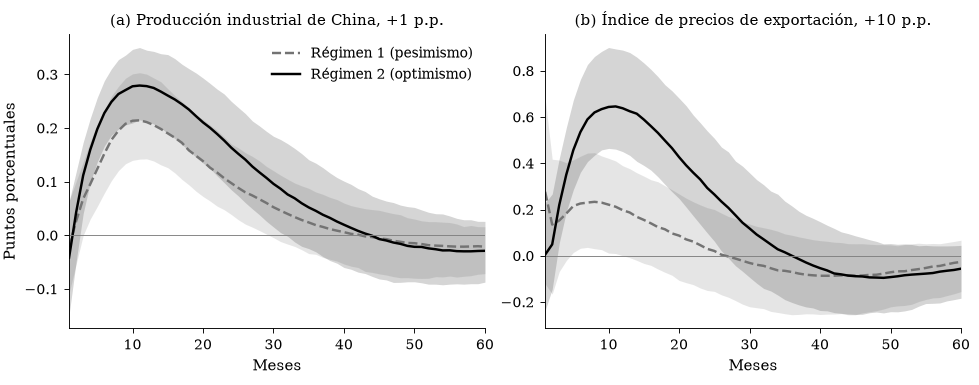

In [6]:
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    for ax, letter, (name, spec) in zip(axes, "ab", specs.items()):
        k = spec.variables.index("g_gdp")
        for reg in ("pesimismo", "optimismo"):
            _band(ax, resp[name][reg][:, :, k], reg)
        _zero(ax); ax.set_xlim(1, g["horizon"]); ax.set_xlabel("Meses")
        ax.set_title(f"({letter}) {spec.label}, +{spec.shock:g} p.p.")
    axes[0].set_ylabel("Puntos porcentuales"); axes[0].legend(loc="upper right")
    fig.tight_layout()
plt.show()

## 3. The structural model (Section 7, Figure 6)

A small linear model with rational expectations and forward-looking investment (`src/tvar_shocks/soe.model`, solved with `irispie`). External demand reaches GDP through export volumes; export prices raise income, which reaches GDP only when it is spent, mostly through investment, whose sensitivity to expected fundamentals is `phi = 1` under optimism and `phi_pes` under pessimism. The external variables follow the median TVAR responses just estimated, so both models face the same shocks. Three parameters (`eta`, `a_p`, `phi_pes`) are calibrated to three TVAR moments: the 12-month pass-through of the China shock under optimism and of the price shock in both regimes. Everything else is fixed in `config.toml`; the China pass-through under pessimism, the 24-month pass-through and the investment and revenue responses are predictions.

In [7]:
s = cfg["structural"]
paths, targets = {}, {}
for name, spec in specs.items():
    for reg in ("pesimismo", "optimismo"):
        median_ext = np.median(resp[name][reg], axis=0)[:, 0] / spec.shock     # external variable, per unit of shock
        paths[(name, reg)] = structural.level_from_yoy(median_ext)
        targets[(name, reg)] = float(pass_through(resp[name][reg], spec, [12]).loc[12, "p50"])
sm = structural.Structural()
cal, err = structural.calibrate(sm, paths, s["fixed"], targets)
print("calibrated:", {k: round(v, 3) for k, v in cal.items()}, f"| max moment error = {err:.1e}")
table, irfs = structural.summary(sm, paths, s["fixed"], cal, g["pass_through"][:2])
(table[(table["version"] == "modelo") & (table["variable"].isin(["y", "i", "rev"]))]
 .pivot_table(index=["shock", "regime"], columns=["variable", "H"], values="pass_through").round(2))

calibrated: {'eta': np.float64(0.609), 'a_p': np.float64(0.668), 'phi_pes': np.float64(0.264)} | max moment error = 1.0e-08


variable            i         rev           y      
H                  12    24    12    24    12    24
shock regime                                       
chn   optimismo  0.22  0.26  0.22  0.25  0.22  0.25
      pesimismo  0.04  0.06  0.20  0.22  0.20  0.22
ipx   optimismo  2.63  3.54  2.59  2.84  0.59  0.84
      pesimismo  0.55  0.78  2.32  2.45  0.32  0.45

### Figure 6: the model against the TVAR

Lines: calibrated model; markers: median generalized responses of the TVAR. The dotted line in panel (b) uses the price path estimated under pessimism with the investment sensitivity of optimism: most of the difference between regimes comes from the lower sensitivity of investment, not from the lower persistence of the shock.

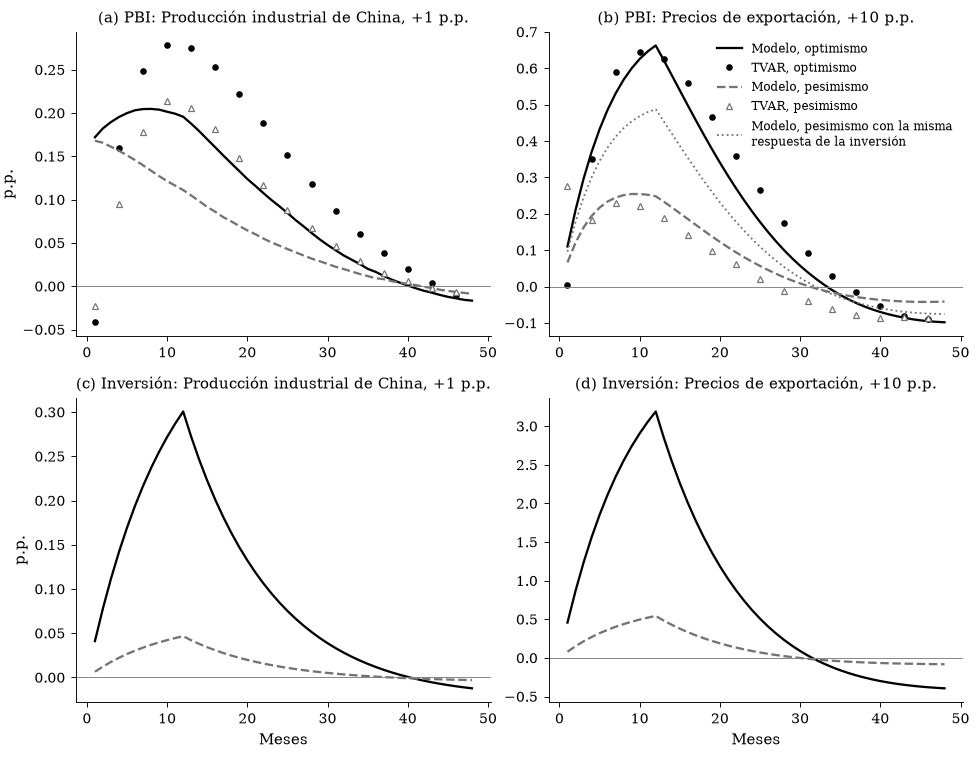

In [8]:
horizon = 48
h = np.arange(1, horizon + 1)
titles = {"chn": "Producción industrial de China, +1 p.p.", "ipx": "Precios de exportación, +10 p.p."}
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(2, 2, figsize=(9, 7))
    for j, shock in enumerate(("chn", "ipx")):
        k = specs[shock].variables.index("g_gdp")
        ax = axes[0, j]
        for reg in ("optimismo", "pesimismo"):
            line, _, ls, _ = REGIME[reg]
            ax.plot(h, irfs[f"modelo__{shock}__{reg}__y"][:horizon], color=line, ls=ls, lw=1.5, label=f"Modelo, {reg}")
            med = np.median(resp[shock][reg], axis=0)[:horizon, k]
            ax.plot(h[::3], med[::3], ls="none", marker="o" if reg == "optimismo" else "^", ms=3.5,
                    mfc="white" if reg == "pesimismo" else "0", mec=line, mew=0.8, label=f"TVAR, {reg}")
        if shock == "ipx":
            ax.plot(h, irfs[f"misma_respuesta__{shock}__pesimismo__y"][:horizon], color="0.45", ls=":", lw=1.2,
                    label="Modelo, pesimismo con la misma\nrespuesta de la inversión")
        _zero(ax); ax.set_title(f"({'ab'[j]}) PBI: {titles[shock]}")
        ax = axes[1, j]
        for reg in ("optimismo", "pesimismo"):
            line, _, ls, _ = REGIME[reg]
            ax.plot(h, irfs[f"modelo__{shock}__{reg}__i"][:horizon], color=line, ls=ls, lw=1.5)
        _zero(ax); ax.set_title(f"({'cd'[j]}) Inversión: {titles[shock]}"); ax.set_xlabel("Meses")
    axes[0, 0].set_ylabel("p.p."); axes[1, 0].set_ylabel("p.p.")
    axes[0, 1].legend(loc="upper right", fontsize=8)
    fig.tight_layout()
plt.show()

The remaining exercises of the paper and of the appendix (conventional responses by regime, the Lenza-Primiceri treatment of the pandemic, local projections, the threshold grid and the estimated threshold, alternative priors and external variables, the joint system with block exogeneity, capital goods imports and fiscal revenue) are reproduced by `make all`.